# Prepare Hard Metrics

In [2]:
import pandas as pd
from datasets import load_dataset, Dataset

dataset = load_dataset('xaviergillard/brabant-xvii-ner')
dataset = dataset['valid'].to_pandas().set_index(["id"]) #pd.concat([d.to_pandas() for _,d in dataset.items()]).set_index(["id"])
#dataset = pd.concat([d.to_pandas() for _,d in dataset.items()]).set_index(["id"])
dataset

/home/xgillard/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating valid split: 100%|██████████| 42/42 [00:00<00:00, 7209.07 examples/s]


,tokens,labels
id,,
282,"[philips, et$ha., doen, te, wetene, dat, wij, ...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, B-PE..."
148,"[albert, ende, isabel, etc, doen, te, wetene, ...","[B-PERS, O, B-PERS, O, O, O, O, O, O, O, O, O,..."
121,"[kaerle, etc., doen, te, wetene, allen, iegewo...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O..."
208,"[philips, etc., doen, te, wetene, allen, tegen...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O..."
161,"[kaerle, etc., doen, te, wetene, allen, iegewo...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O..."
219,"[albert, ende, isabel, clara, eugeni$, infante...","[B-PERS, O, B-PERS, I-PERS, I-PERS, O, O, B-LO..."
355,"[philips, bijder, gracien, goidts, coninck, va...","[B-PERS, O, O, O, O, O, B-LOC, O, B-LOC, O, B-..."
37,"[remis, jans, braken, kaerle, etc., doen, te, ...","[O, B-PERS, I-PERS, I-PERS, O, O, O, O, O, O, ..."
235,"[copie, van, eenre, remissien, voere, henry, d...","[O, O, O, O, O, B-PERS, I-PERS, I-PERS, I-PERS..."


In [3]:
import pandas as pd

from typing import NamedTuple

class Entities(NamedTuple):
    persons:   set[str]
    dates:     set[str]
    locations: set[str]

    @staticmethod
    # supprime les répétitions et overlap
    def __no_overlap(s):
        l = sorted(list(s), key=len, reverse=True)
        r = []
        for e in l:
            for o in r:
                if str(e)in str(o):
                    break
            else:
                r.append(str(e))
        return set(r)

    def __or__(self, other: "Entities") -> "Entities":
        persons   = Entities.__no_overlap(self.persons | other.persons)
        dates     = Entities.__no_overlap(self.dates | other.dates)
        locations = Entities.__no_overlap(self.locations | other.locations)
        return Entities(persons, dates, locations)

    @staticmethod
    def from_pandas(df: pd.DataFrame) -> "Entities":
        persons   = { e for e in df[df["label"] == "PERS"]["entity"] }
        dates     = { e for e in df[df["label"] == "DATE"]["entity"] }
        locations = { e for e in df[df["label"] == "LOC"]["entity"] }
        return Entities(persons, dates, locations)

    @staticmethod
    def from_words_labels(tokens: list[str], labels: list[str]) -> "Entities":
        persons   = []
        dates     = []
        locations = []
        #
        current = None
        ctype   = None
        for t,l in zip(tokens, labels):
            if l == 'O':
                if current:
                    match ctype:
                        case 'PERS': persons.append(current)
                        case 'DATE': dates.append(current)
                        case 'LOC': locations.append(current)
                current = None
                ctype   = None
            elif l.startswith('B-'):
                if current:
                    match ctype:
                        case 'PERS': persons.append(current)
                        case 'DATE': dates.append(current)
                        case 'LOC': locations.append(current)
                current = t
                ctype   = l[2:]
            elif l in [f"I-{ctype}", "IGN"]:
                current = f"{current} {t}"
        #
        persons   = Entities.__no_overlap(persons)
        dates     = Entities.__no_overlap(dates)
        locations = Entities.__no_overlap(locations)
        #
        return Entities(persons, dates, locations)

    @staticmethod
    def from_tokenids_labels(tokens: list[int], wordids: list[int], labels: list[str], words: list[str]) -> "Entities":
        persons   = []
        dates     = []
        locations = []
        #
        current = None
        prevwid = None
        ctype   = None
        for t,w,l in zip(tokens, wordids, labels):
            if l == 'O':
                if current:
                    match ctype:
                        case 'PERS': persons.append(current)
                        case 'DATE': dates.append(current)
                        case 'LOC': locations.append(current)
                current = None
                ctype   = None
                prevwid = None
            elif l.startswith('B-'):
                match ctype:
                    case 'PERS': persons.append(current)
                    case 'DATE': dates.append(current)
                    case 'LOC': locations.append(current)
                current = words[w]
                ctype   = l[2:]
                prevwid = w
            elif l in [f"I-{ctype}", "IGN"]:
                if prevwid != w:
                    current = f"{current} {words[w]}"
                    prevwid = w
        #
        persons   = Entities.__no_overlap(persons)
        dates     = Entities.__no_overlap(dates)
        locations = Entities.__no_overlap(locations)
        #
        return Entities(persons, dates, locations)
        

In [4]:
dataset['entities'] = dataset.apply(lambda row: Entities.from_words_labels(row['tokens'], row['labels']), axis=1)
dataset

,tokens,labels,entities
id,,,
282,"[philips, et$ha., doen, te, wetene, dat, wij, ...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, B-PE...","({heere prelaet van perck, jaecques meerts, ca..."
148,"[albert, ende, isabel, etc, doen, te, wetene, ...","[B-PERS, O, B-PERS, O, O, O, O, O, O, O, O, O,...","({peeter stinmetser, $$ willems, geeraert kran..."
121,"[kaerle, etc., doen, te, wetene, allen, iegewo...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O...","({gommaer vanden dycke, bernaert van roosbroec..."
208,"[philips, etc., doen, te, wetene, allen, tegen...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O...","({de langhe, hendrick vanden bossche, heyndric..."
161,"[kaerle, etc., doen, te, wetene, allen, iegewo...","[B-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O...","({jan de mol, cleermaeckere, jan mol, thomaes ..."
219,"[albert, ende, isabel, clara, eugeni$, infante...","[B-PERS, O, B-PERS, I-PERS, I-PERS, O, O, B-LO...","({i cools, isabel clara eugeni$, matheeus trui..."
355,"[philips, bijder, gracien, goidts, coninck, va...","[B-PERS, O, O, O, O, O, B-LOC, O, B-LOC, O, B-...","({gilis de smeth, steven, willem cool, antheun..."
37,"[remis, jans, braken, kaerle, etc., doen, te, ...","[O, B-PERS, I-PERS, I-PERS, O, O, O, O, O, O, ...","({jan de jonge, jan de backer, jan braken, bou..."
235,"[copie, van, eenre, remissien, voere, henry, d...","[O, O, O, O, O, B-PERS, I-PERS, I-PERS, I-PERS...","({henricken clemens, andriesen, henry de wolff..."


In [5]:
def totals(x):
    a, b, c = 0, 0, 0
    for ai,bi,ci in x:
        a+=ai
        b+=bi
        c+=ci
    return a,b,c

def precisions(intersect, p_size):
    return tuple( float(i) / float(j) if j > 0 else 0 for i,j in zip(intersect, p_size))

def recalls(intersect, t_size):
    return tuple( float(i) / float(j) if j > 0 else 0 for i,j in zip(intersect, t_size))

def f1s(intersect, p_size, t_size):
    precs = precisions(intersect, p_size)
    recs  = recalls(intersect, t_size)
    return tuple( (2*p*r) / (p+r) if p+r > 0 else 0 for p,r in zip(precs, recs))

def report(pvf):
    intersect = totals(pvf['intersection_size'])
    p_size    = totals(pvf['p_size'])
    t_size    = totals(pvf['t_size'])
    
    precs  = precisions(intersect, p_size)
    recs   = recalls(intersect, t_size)
    gmeans = f1s(intersect, p_size, t_size)

    return pd.DataFrame({'entity':    ['persons', 'dates', 'locations'],
                         'precision': precs,
                         'recall'   : recs,
                         'f1'       : gmeans})

In [6]:
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

from tqdm import tqdm

def measure(dataset, name):
    vftok = AutoTokenizer.from_pretrained(name)
    vfmod = AutoModelForTokenClassification.from_pretrained(name).eval().cuda()
    
    vfr = []
    for _, row in tqdm(dataset.iterrows()):
        encoded = vftok(
            list(row['tokens']), 
            max_length=510,
            padding=True,
            truncation=True,
            stride=20,
            is_split_into_words=True,
            return_overflowing_tokens=True,
        )
        data = []
        for i in range(len(encoded['input_ids'])):
            out   = vfmod(
                input_ids=torch.tensor(encoded['input_ids'][i], dtype=torch.int, device="cuda").unsqueeze(0), 
                attention_mask=torch.tensor(encoded['attention_mask'][i], dtype=torch.int, device="cuda").unsqueeze(0),
            )
            preds = out.logits.argmax(-1)[0]
            prds  = [ vfmod.config.id2label[l.item()] for l in preds ]
            ent   = Entities.from_tokenids_labels(encoded['input_ids'][i], encoded.encodings[i].word_ids, prds, row['tokens'])
            data.append(ent)
        # fold
        entities = Entities(set(), set(), set())
        for e in data:
            entities = entities | e
        vfr.append(entities)
        
    pvf = pd.DataFrame({"predictions": vfr, "ground_truth": dataset["entities"]})
    pvf["intersection_size"] = pvf.apply(lambda row: tuple(len(a & b) for a,b in zip(row['predictions'], row['ground_truth'])), axis=1)
    pvf["p_size"] = pvf.apply(lambda row: tuple(len(a) for a in row['predictions']), axis=1)
    pvf["t_size"] = pvf.apply(lambda row: tuple(len(a) for a in row['ground_truth']), axis=1)

    #print(name)
    pvf = report(pvf)
    pvf["model"] = name.split('/')[1]
    #print(pvf)
    return pvf
    

In [7]:
xlm = pd.concat([
    measure(dataset, "xaviergillard/xlm-roberta-large-vieille-france",),
    measure(dataset, "xaviergillard/xlm-roberta-large-vieille-france-v2",),
    measure(dataset, "xaviergillard/brabrant-xvii-ner",),
], axis=0)
xlm

42it [00:15,  2.76it/s]
42it [00:15,  2.71it/s]
42it [00:14,  2.84it/s]


,entity,precision,recall,f1,model
0,persons,0.396752,0.450000,0.421702,xlm-roberta-large-vieille-france
1,dates,0.142857,0.040000,0.062500,xlm-roberta-large-vieille-france
2,locations,0.544186,0.330508,0.411248,xlm-roberta-large-vieille-france
0,persons,0.837150,0.865789,0.851229,xlm-roberta-large-vieille-france-v2
1,dates,0.352273,0.413333,0.380368,xlm-roberta-large-vieille-france-v2
2,locations,0.714286,0.677966,0.695652,xlm-roberta-large-vieille-france-v2
0,persons,0.783163,0.807895,0.795337,brabrant-xvii-ner
1,dates,0.539683,0.453333,0.492754,brabrant-xvii-ner
2,locations,0.644205,0.675141,0.659310,brabrant-xvii-ner


In [8]:
import json
import sqlite3
import pandas as pd

def measure_llm(name):
    db = sqlite3.connect("unified.db")
    cur = db.cursor()
    cur.execute("select labeling from labeling where model = ?;", (name,))
    res = cur.fetchall()
    
    docids   = []
    entities = []
    for r in res:
        jsndata  = json.loads(r[0])
        docdata  = jsndata["documentdata"]
        docid    = int(jsndata["id"])
        if not docdata:
            #print(f"skip {docid}")
            continue
        persons  = set( f"{p['firstname']} {p['lastname']}".lower() for p in docdata['persons'] )# + [ f"{p['lastname']} {p['firstname']}".lower() for p in docdata['persons'] ]
        dates    = set( (docdata.get('act_date', None), docdata.get('fact_date', None)) )
        locations= set( l['name'] for l in docdata['locations'] )
    
        docids.append(docid)
        entities.append(Entities(persons, dates, locations))
    
    df = pd.DataFrame({"id": docids, "predictions": entities}).set_index('id')
    df['ground_truth'] = dataset['entities']
    df = df.dropna()
    
    df["intersection_size"] = df.apply(lambda row: tuple(len(a & b) for a,b in zip(row['predictions'], row['ground_truth'])), axis=1)
    df["p_size"] = df.apply(lambda row: tuple(len(a) for a in row['predictions']), axis=1)
    df["t_size"] = df.apply(lambda row: tuple(len(a) for a in row['ground_truth']), axis=1)

    print(name)
    df = report(df)
    df["model"] = name
    return df

In [9]:
llm = pd.concat([
    measure_llm('gpt4o-mini'),
    measure_llm('llama'),
    measure_llm('mistral7b'),
    measure_llm('mistralnemo'),
], axis=0)
llm

gpt4o-mini
llama
mistral7b
mistralnemo


,entity,precision,recall,f1,model
0,persons,0.515528,0.218421,0.306839,gpt4o-mini
1,dates,0.000000,0.000000,0.000000,gpt4o-mini
2,locations,0.011236,0.002825,0.004515,gpt4o-mini
0,persons,0.409302,0.231579,0.295798,llama
1,dates,0.013333,0.013333,0.013333,llama
2,locations,0.000000,0.000000,0.000000,llama
0,persons,0.428571,0.163488,0.236686,mistral7b
1,dates,0.016949,0.014286,0.015504,mistral7b
2,locations,0.231884,0.045845,0.076555,mistral7b
0,persons,0.503226,0.205263,0.291589,mistralnemo


In [10]:
recapdf = pd.concat([xlm, llm], axis=0, ignore_index=True).set_index(["entity", "model"])
recapdf.columns.name = "metric"
recapdf = recapdf * 100

In [11]:
recapdf.loc["persons"]["f1"]

model
xlm-roberta-large-vieille-france       42.170160
xlm-roberta-large-vieille-france-v2    85.122898
brabrant-xvii-ner                      79.533679
gpt4o-mini                             30.683919
llama                                  29.579832
mistral7b                              23.668639
mistralnemo                            29.158879
Name: f1, dtype: float64

/tmp/ipykernel_6703/3321458148.py:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


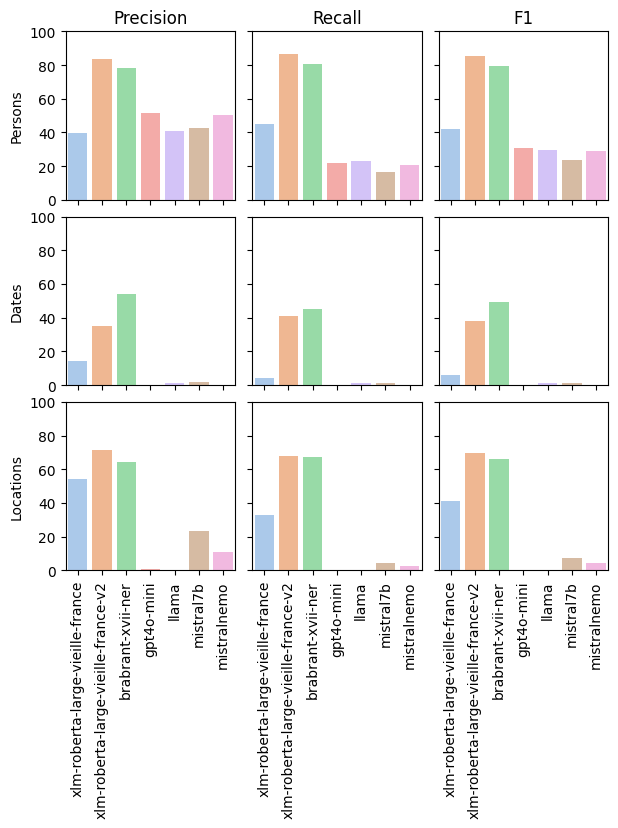

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

with sns.color_palette('pastel', n_colors=10) as palette:
    fig, axes = plt.subplots(3, 3, sharex=True, sharey=True)

    persons   = recapdf.loc["persons"]
    dates     = recapdf.loc["dates"]
    locations = recapdf.loc["locations"]
    #
    sns.barplot(data=persons, x="model", y="precision", hue="model", ax=axes[0, 0])
    sns.barplot(data=persons, x="model", y="recall",    hue="model", ax=axes[0, 1])
    sns.barplot(data=persons, x="model", y="f1",        hue="model", ax=axes[0, 2])
    #
    sns.barplot(data=dates, x="model", y="precision", hue="model", ax=axes[1, 0])
    sns.barplot(data=dates, x="model", y="recall",    hue="model", ax=axes[1, 1])
    sns.barplot(data=dates, x="model", y="f1",        hue="model", ax=axes[1, 2])
    #
    sns.barplot(data=locations, x="model", y="precision", hue="model", ax=axes[2, 0])
    sns.barplot(data=locations, x="model", y="recall",    hue="model", ax=axes[2, 1])
    sns.barplot(data=locations, x="model", y="f1",        hue="model", ax=axes[2, 2])
    #
    for i in range(3):
        for j in range(3):
            axes[i,j].set_ylim(0, 100)
            axes[i,j].tick_params(axis='x', rotation=90)
            axes[i,j].set_xlabel('')
            axes[i,j].set_ylabel('')
    #
    axes[0,0].set_ylabel("Persons")
    axes[1,0].set_ylabel("Dates")
    axes[2,0].set_ylabel("Locations")
    #
    axes[0,0].set_title("Precision")
    axes[0,1].set_title("Recall")
    axes[0,2].set_title("F1")
   
    fig.set_figwidth(7)
    fig.set_figheight(7)
    fig.subplots_adjust(wspace=0.1, hspace=0.1)
    fig.show()


In [14]:
fig.savefig("hard_metrics_full.png")